In [1]:
import pandas as pd
import time

file = "SpectrumData_2021Y.xlsx"

sheets = [
    "wavelength",
    "darkcurrent",
    "trainSet",
    "testSetLowNoise"
]

data = {}

for sheet in sheets:
    start = time.time()
    print(f"Loading {sheet}...", flush=True)

    data[sheet] = pd.read_excel(file, sheet_name=sheet)

    print(
        f"Loaded {sheet}: {data[sheet].shape} "
        f"in {time.time() - start:.1f} seconds",
        flush=True
    )

wavelength = data["wavelength"]
darkcurrent = data["darkcurrent"]
trainSet = data["trainSet"]
testSetLowNoise = data["testSetLowNoise"]

Loading wavelength...
Loaded wavelength: (224, 3) in 0.1 seconds
Loading darkcurrent...
Loaded darkcurrent: (640, 224) in 0.4 seconds
Loading trainSet...
Loaded trainSet: (50000, 227) in 37.1 seconds
Loading testSetLowNoise...
Loaded testSetLowNoise: (100000, 227) in 82.0 seconds


Preparing training features...

Clusters per category:
class_id
PE     12
PP     12
PET    12
PS     12
PVC    12

Training rows: 50,000
Spatial clusters: 60
Validation folds: 5

Learning thresholds and vote weights...
Best settings: {'weights__C': 0.1}
Mean validation macro F1: 0.8323

Evaluating on testSetLowNoise...


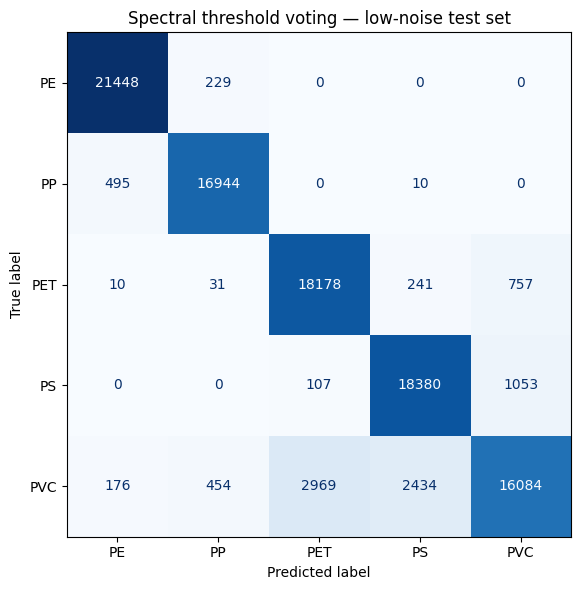


Test metrics:
test_accuracy: 0.9103
test_macro_precision: 0.9111
test_macro_recall: 0.9149
test_macro_f1: 0.9104

Learned rules:


,feature,requested_lower_nm,requested_upper_nm,actual_lower_nm,actual_upper_nm,centre_channels,left_shoulder_mean_nm,right_shoulder_mean_nm,active,threshold_dip_depth,weight_PE,weight_PP,weight_PET,weight_PS,weight_PVC
0,1119_nm,1114,1124,1115.79,1122.84,3,1105.2300,1133.4067,True,0.0005,0.3545,0.0031,1.6030,-2.4700,0.5095
1,1130_nm,1125,1135,1126.36,1133.41,3,1115.7933,1143.9767,True,0.0199,-2.0179,-0.4248,2.2180,-0.7281,0.9529
2,1144_nm,1139,1149,1140.45,1147.50,3,1129.8833,1158.0733,True,0.0339,-3.0268,-1.3209,-0.6681,4.4344,0.5814
3,1212_nm,1195,1230,1196.84,1228.58,10,1186.2667,1239.1567,True,0.0546,5.1170,2.1707,-2.6948,-1.3208,-3.2720
4,1410_nm,1390,1435,1390.94,1433.34,13,1382.1050,1443.9433,True,0.1063,2.7259,-0.4892,-0.1001,-1.2315,-0.9052
5,1539_nm,1520,1560,1521.74,1557.13,11,1511.1300,1567.7400,True,0.0068,2.7264,-1.2195,-0.1137,-1.6628,0.2696
6,1663_nm,1645,1680,1645.64,1677.53,10,1636.7900,1688.1633,True,-0.0263,-0.6683,-1.7877,4.2013,0.1590,-1.9043



Results saved to: /Users/williamronan/PythonTools/HyperspectralPVCSort/results/spectral_threshold_voting


In [3]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import label
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. Configuration
# ============================================================

RESULTS_DIR = Path("results") / "spectral_threshold_voting"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CHANNELS = [f"ch.{i}" for i in range(1, 225)]
CLASS_NAMES = {1: "PE", 2: "PP", 3: "PET", 4: "PS", 5: "PVC"}
CLASS_IDS = list(CLASS_NAMES)
RANDOM_STATE = 42

REGIONS = [
    ("1119_nm", 1114, 1124),
    ("1130_nm", 1125, 1135),
    ("1144_nm", 1139, 1149),
    ("1212_nm", 1195, 1230),
    ("1410_nm", 1390, 1435),
    ("1539_nm", 1520, 1560),
    ("1663_nm", 1645, 1680)
]

SHOULDER_WIDTH_NM = 10
SHOULDER_GAP_NM = 3

# ============================================================
# 2. References and preprocessing
# ============================================================

wavelength_nm = (
    wavelength.set_index("channel")
    .loc[range(1, 225), "wavelength"]
    .to_numpy(dtype=float)
)

dark_values = darkcurrent[CHANNELS].to_numpy(dtype=float)

if not np.isfinite(dark_values).all():
    raise ValueError("Dark-current reference contains invalid values.")

dark_vector = dark_values.mean(axis=0)

if (
    not np.isfinite(wavelength_nm).all()
    or not (np.diff(wavelength_nm) > 0).all()
):
    raise ValueError("Check wavelength values and channel order.")


def preprocess(frame):
    """Subtract mean dark current and normalize each spectrum to [0, 1]."""
    spectra = frame[CHANNELS].to_numpy(dtype=float)

    if not np.isfinite(spectra).all():
        raise ValueError("Spectra contain missing or non-finite values.")

    corrected = spectra - dark_vector
    row_min = corrected.min(axis=1, keepdims=True)
    row_range = np.ptp(corrected, axis=1, keepdims=True)

    if np.any(row_range == 0):
        raise ValueError(
            "Constant spectra detected. Inspect these rows before training."
        )

    return (corrected - row_min) / row_range


def get_labels(frame):
    values = pd.to_numeric(frame["class_id"], errors="raise").to_numpy()

    if not np.isin(values, CLASS_IDS).all():
        raise ValueError("Expected class labels 1–5.")

    return values.astype(int)


# ============================================================
# 3. Fixed local absorption features
# ============================================================

def extract_features(spectra):
    """
    Estimate local dip depth relative to a line connecting nearby shoulders.
    Positive values indicate a local dip.
    """
    features = {}
    metadata = []

    for name, lower, upper in REGIONS:
        centre_mask = (
            (wavelength_nm >= lower)
            & (wavelength_nm <= upper)
        )
        left_mask = (
            (wavelength_nm >= lower - SHOULDER_GAP_NM - SHOULDER_WIDTH_NM)
            & (wavelength_nm <= lower - SHOULDER_GAP_NM)
        )
        right_mask = (
            (wavelength_nm >= upper + SHOULDER_GAP_NM)
            & (wavelength_nm <= upper + SHOULDER_GAP_NM + SHOULDER_WIDTH_NM)
        )

        if not all(mask.any() for mask in [
            centre_mask, left_mask, right_mask
        ]):
            raise ValueError(f"Insufficient channels around {name}.")

        left_signal = spectra[:, left_mask].mean(axis=1)
        right_signal = spectra[:, right_mask].mean(axis=1)
        centre_signal = spectra[:, centre_mask].mean(axis=1)

        left_wave = wavelength_nm[left_mask].mean()
        right_wave = wavelength_nm[right_mask].mean()
        centre_wave = wavelength_nm[centre_mask].mean()

        fraction = (centre_wave - left_wave) / (right_wave - left_wave)
        continuum = left_signal + fraction * (right_signal - left_signal)

        features[name] = continuum - centre_signal

        metadata.append({
            "feature": name,
            "requested_lower_nm": lower,
            "requested_upper_nm": upper,
            "actual_lower_nm": wavelength_nm[centre_mask].min(),
            "actual_upper_nm": wavelength_nm[centre_mask].max(),
            "centre_channels": int(centre_mask.sum()),
            "left_shoulder_mean_nm": left_wave,
            "right_shoulder_mean_nm": right_wave
        })

    return pd.DataFrame(features), pd.DataFrame(metadata)


print("Preparing training features...", flush=True)

X_train, feature_metadata = extract_features(preprocess(trainSet))
y_train = get_labels(trainSet)

feature_metadata.to_csv(
    RESULTS_DIR / "feature_regions.csv", index=False
)

# ============================================================
# 4. Identify spatial clusters
# ============================================================

coords = trainSet[
    ["coord_lateral", "coord_driving"]
].to_numpy(dtype=float)

if not np.isfinite(coords).all() or not (coords % 1 == 0).all():
    raise ValueError("Grouping requires valid integer coordinates.")

coords = coords.astype(int)
coord_min = coords.min(axis=0)
offsets = coords - coord_min

occupancy = np.zeros(
    (offsets[:, 1].max() + 1, offsets[:, 0].max() + 1),
    dtype=bool
)
occupancy[offsets[:, 1], offsets[:, 0]] = True

cluster_grid, cluster_count = label(
    occupancy,
    structure=np.ones((3, 3), dtype=int)
)

groups = cluster_grid[offsets[:, 1], offsets[:, 0]]

group_table = pd.DataFrame({
    "cluster": groups,
    "class_id": y_train
})

if group_table.groupby("cluster")["class_id"].nunique().gt(1).any():
    raise ValueError(
        "Some spatial clusters contain multiple categories. Inspect grouping."
    )

# One row per cluster, with its category label.
object_table = (
    group_table.drop_duplicates("cluster")
    .sort_values("cluster")
    .reset_index(drop=True)
)

groups_per_class = (
    object_table["class_id"]
    .value_counts()
    .reindex(CLASS_IDS, fill_value=0)
)

print("\nClusters per category:")
print(groups_per_class.rename(index=CLASS_NAMES).to_string())

n_splits = min(5, int(groups_per_class.min()))

if n_splits < 2:
    raise ValueError(
        "Need at least two spatial clusters per category for validation."
    )

# ============================================================
# 5. Stratify clusters, then map folds back to measurement rows
# ============================================================

object_cv = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=RANDOM_STATE
)

folds = []
fold_records = []
validation_fold = np.full(len(trainSet), -1, dtype=int)

for fold_number, (fit_objects, val_objects) in enumerate(
    object_cv.split(
        object_table["cluster"],
        object_table["class_id"]
    ),
    start=1
):
    fit_groups = object_table.iloc[fit_objects]["cluster"].to_numpy()
    val_groups = object_table.iloc[val_objects]["cluster"].to_numpy()

    fit_indices = np.flatnonzero(np.isin(groups, fit_groups))
    val_indices = np.flatnonzero(np.isin(groups, val_groups))

    if np.intersect1d(fit_groups, val_groups).size:
        raise ValueError("A cluster appears in both sides of a fold.")

    for indices in [fit_indices, val_indices]:
        if set(np.unique(y_train[indices])) != set(CLASS_IDS):
            raise ValueError("A fold is missing a category.")

    folds.append((fit_indices, val_indices))
    validation_fold[val_indices] = fold_number

    for class_id in CLASS_IDS:
        fold_records.append({
            "fold": fold_number,
            "plastic": CLASS_NAMES[class_id],
            "training_clusters": int(
                (
                    object_table.iloc[fit_objects]["class_id"] == class_id
                ).sum()
            ),
            "validation_clusters": int(
                (
                    object_table.iloc[val_objects]["class_id"] == class_id
                ).sum()
            ),
            "training_rows": int(
                (y_train[fit_indices] == class_id).sum()
            ),
            "validation_rows": int(
                (y_train[val_indices] == class_id).sum()
            )
        })

fold_summary = pd.DataFrame(fold_records)
fold_summary.to_csv(
    RESULTS_DIR / "validation_fold_summary.csv", index=False
)

pd.DataFrame({
    "row_position": np.arange(len(trainSet)),
    "cluster": groups,
    "class_id": y_train,
    "validation_fold": validation_fold
}).to_csv(
    RESULTS_DIR / "training_groups.csv", index=False
)

print(f"\nTraining rows: {len(X_train):,}")
print(f"Spatial clusters: {cluster_count}")
print(f"Validation folds: {n_splits}")

# ============================================================
# 6. Learn one threshold per spectral feature
# ============================================================

class SpectralThresholds(BaseEstimator, TransformerMixin):
    def __init__(self, random_state=42):
        self.random_state = random_state

    def fit(self, X, y):
        values = np.asarray(X, dtype=float)
        self.n_features_in_ = values.shape[1]
        thresholds = []
        active_features = []

        for column in range(self.n_features_in_):
            stump = DecisionTreeClassifier(
                max_depth=1,
                criterion="entropy",
                class_weight="balanced",
                random_state=self.random_state
            )
            stump.fit(values[:, [column]], y)

            active = stump.tree_.node_count > 1
            active_features.append(active)
            thresholds.append(
                float(stump.tree_.threshold[0]) if active else np.nan
            )

        self.thresholds_ = np.asarray(thresholds)
        self.active_ = np.asarray(active_features)
        return self

    def transform(self, X):
        values = np.asarray(X, dtype=float)

        if values.shape[1] != self.n_features_in_:
            raise ValueError("Unexpected number of spectral features.")

        return (
            (values > self.thresholds_) & self.active_
        ).astype(float)


pipeline = Pipeline([
    ("thresholds", SpectralThresholds(random_state=RANDOM_STATE)),
    ("weights", LogisticRegression(
        class_weight="balanced",
        max_iter=3000,
        solver="lbfgs",
        random_state=RANDOM_STATE
    ))
])

# ============================================================
# 7. Tune vote-weight regularization
# ============================================================

search = GridSearchCV(
    estimator=pipeline,
    param_grid={"weights__C": [0.01, 0.1, 1, 10, 100]},
    scoring={
        "accuracy": "accuracy",
        "macro_precision": "precision_macro",
        "macro_recall": "recall_macro",
        "macro_f1": "f1_macro"
    },
    refit="macro_f1",
    cv=folds,
    n_jobs=-1,
    return_train_score=True,
    error_score="raise"
)

print("\nLearning thresholds and vote weights...", flush=True)
search.fit(X_train, y_train)

# GridSearchCV refits the best configuration on the full training set.
best_model = search.best_estimator_

pd.DataFrame(search.cv_results_).to_csv(
    RESULTS_DIR / "cross_validation_results.csv", index=False
)

print(f"Best settings: {search.best_params_}")
print(f"Mean validation macro F1: {search.best_score_:.4f}")

# ============================================================
# 8. Evaluate on testSetLowNoise
# ============================================================

print("\nEvaluating on testSetLowNoise...", flush=True)

X_test, _ = extract_features(preprocess(testSetLowNoise))
y_test = get_labels(testSetLowNoise)

predictions = best_model.predict(X_test)
probabilities = best_model.predict_proba(X_test)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_test,
    predictions,
    labels=CLASS_IDS,
    average="macro",
    zero_division=0
)

metrics = {
    "test_accuracy": float(accuracy_score(y_test, predictions)),
    "test_macro_precision": float(precision),
    "test_macro_recall": float(recall),
    "test_macro_f1": float(f1),
    "best_validation_macro_f1": float(search.best_score_),
    "best_C": float(search.best_params_["weights__C"]),
    "validation_folds": n_splits,
    "training_clusters": int(cluster_count),
    "training_rows": len(X_train),
    "test_rows": len(X_test)
}

with open(RESULTS_DIR / "metrics.json", "w") as handle:
    json.dump(metrics, handle, indent=2)

report = classification_report(
    y_test,
    predictions,
    labels=CLASS_IDS,
    target_names=list(CLASS_NAMES.values()),
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    RESULTS_DIR / "classification_report.csv"
)

prediction_table = pd.DataFrame({
    "row_position": np.arange(len(y_test)),
    "true_class": y_test,
    "predicted_class": predictions,
    "correct": predictions == y_test
})

weight_step = best_model.named_steps["weights"]

for column, class_id in enumerate(weight_step.classes_):
    prediction_table[f"probability_{CLASS_NAMES[class_id]}"] = (
        probabilities[:, column]
    )

prediction_table.to_csv(
    RESULTS_DIR / "test_predictions.csv", index=False
)

cm = confusion_matrix(y_test, predictions, labels=CLASS_IDS)

pd.DataFrame(
    cm,
    index=pd.Index(CLASS_NAMES.values(), name="true_category"),
    columns=pd.Index(CLASS_NAMES.values(), name="predicted_category")
).to_csv(RESULTS_DIR / "confusion_matrix.csv")

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(
    cm,
    display_labels=list(CLASS_NAMES.values())
).plot(ax=ax, cmap="Blues", colorbar=False)

ax.set_title("Spectral threshold voting — low-noise test set")
fig.tight_layout()
fig.savefig(
    RESULTS_DIR / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ============================================================
# 9. Save learned rules and model
# ============================================================

threshold_step = best_model.named_steps["thresholds"]

rules = feature_metadata.copy()
rules["active"] = threshold_step.active_
rules["threshold_dip_depth"] = threshold_step.thresholds_

for class_id, weights in zip(weight_step.classes_, weight_step.coef_):
    rules[f"weight_{CLASS_NAMES[class_id]}"] = weights

rules.to_csv(
    RESULTS_DIR / "learned_rules.csv", index=False
)

pd.DataFrame({
    "plastic": [CLASS_NAMES[c] for c in weight_step.classes_],
    "intercept": weight_step.intercept_
}).to_csv(
    RESULTS_DIR / "class_intercepts.csv", index=False
)

# To load this bundle later, first define SpectralThresholds.
# Use preprocess/extract_features above with the saved reference settings.
joblib.dump(
    {
        "model": best_model,
        "dark_vector": dark_vector,
        "wavelength_nm": wavelength_nm,
        "channels": CHANNELS,
        "regions": REGIONS,
        "shoulder_width_nm": SHOULDER_WIDTH_NM,
        "shoulder_gap_nm": SHOULDER_GAP_NM,
        "normalization": "per-spectrum min-max after dark subtraction",
        "class_names": CLASS_NAMES
    },
    RESULTS_DIR / "model_bundle.joblib"
)

print("\nTest metrics:")
for name in [
    "test_accuracy",
    "test_macro_precision",
    "test_macro_recall",
    "test_macro_f1"
]:
    print(f"{name}: {metrics[name]:.4f}")

print("\nLearned rules:")
display(rules.round(4))

print(f"\nResults saved to: {RESULTS_DIR.resolve()}")